<a href="https://colab.research.google.com/github/Oppositecity/oppositecity.github.io/blob/main/morphogenesis_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MORPHOGENESIS — full glyph training

One neural cellular automaton that learns to grow every glyph below from a single cell, rebuild itself into another glyph, and heal wounds.

**Colab:** Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**. Training takes roughly 1–2 hours. The last cell downloads `weights.json`; send that file back to Claude.

**On an M1 Mac instead:** in Terminal, `pip3 install jax optax pillow fonttools`, put `nca_glyphs.py` and the fonts from the first cell in one folder, then run the command shown in the training cell (drop the leading `!`, put the glyphs in `glyphs.txt`, and replace `{ITERS}` with 16000). If it stops, run it again: it resumes from its checkpoint.

In [1]:
# fonts: Courier Prime for letters; Noto fills in Greek and symbols Courier Prime lacks
!pip -q install optax pillow fonttools
!wget -q -O CourierPrime-Bold.ttf https://raw.githubusercontent.com/google/fonts/main/ofl/courierprime/CourierPrime-Bold.ttf
!wget -q -O NotoSansMono.ttf "https://raw.githubusercontent.com/google/fonts/main/ofl/notosansmono/NotoSansMono%5Bwdth,wght%5D.ttf"
!wget -q -O NotoSansMath.ttf https://raw.githubusercontent.com/google/fonts/main/ofl/notosansmath/NotoSansMath-Regular.ttf
!wget -q -O NotoSansSymbols.ttf "https://raw.githubusercontent.com/google/fonts/main/ofl/notosanssymbols/NotoSansSymbols%5Bwght%5D.ttf"
!wget -q -O NotoSansSymbols2.ttf https://raw.githubusercontent.com/google/fonts/main/ofl/notosanssymbols2/NotoSansSymbols2-Regular.ttf
import jax; print(jax.devices())

[CudaDevice(id=0)]


In [2]:
%%writefile nca_glyphs.py
"""
Goal-conditioned Neural Cellular Automata for glyphs.
One shared rule; each cell also reads a goal code (which glyph to become).
 - metamorphosis: pool states get re-assigned new goals during training
 - regeneration: pool states get damaged during training
 - asemics: goal codes are noised during training so in-between codes stay letter-like

Runs on CPU, Colab GPU, or Apple Silicon (jax CPU is fine on M1).
  python nca_glyphs.py --glyphs "ABC..." --font CourierPrime-Bold.ttf --minutes 9 --out run1
Re-running with the same --out resumes from its checkpoint.
"""
import argparse, json, os, time, pickle
import numpy as np
import jax, jax.numpy as jnp
import optax
from PIL import Image, ImageDraw, ImageFont

p = argparse.ArgumentParser()
p.add_argument("--glyphs", default="ABCDEFGHIJKLMNOPQRSTUVWXYZ")
p.add_argument("--glyphs_file", default="", help="read the glyph set from a UTF-8 text file")
p.add_argument("--font", default="CourierPrime-Bold.ttf")
p.add_argument("--fallback_fonts", default="", help="comma list of fonts tried when --font lacks a glyph")
p.add_argument("--grid", type=int, default=32)
p.add_argument("--box", type=int, default=24, help="glyph size inside the grid")
p.add_argument("--channels", type=int, default=16)
p.add_argument("--goal_dim", type=int, default=8)
p.add_argument("--hidden", type=int, default=96)
p.add_argument("--batch", type=int, default=8)
p.add_argument("--pool", type=int, default=1024)
p.add_argument("--lr", type=float, default=2e-3)
p.add_argument("--iters", type=int, default=6000)
p.add_argument("--minutes", type=float, default=0, help="stop after this wall time (0 = run to --iters)")
p.add_argument("--warmup", type=int, default=1500, help="iterations of pure growth before morphing/damage")
p.add_argument("--seeds", type=int, default=2, help="fresh seeds per batch")
p.add_argument("--steps", default="48,72")
p.add_argument("--morph_p", type=float, default=0.35)
p.add_argument("--goal_noise", type=float, default=0.15)
p.add_argument("--out", default="run")
p.add_argument("--seed", type=int, default=0)
a = p.parse_args()
os.makedirs(a.out, exist_ok=True)
C, G, H, W = a.channels, a.goal_dim, a.grid, a.grid
GLYPHS = list(dict.fromkeys(open(a.glyphs_file, encoding="utf-8").read().strip() if a.glyphs_file else a.glyphs))
GLYPHS = [g for g in GLYPHS if not g.isspace()]
N = len(GLYPHS)

# ---------- targets ----------
from fontTools.ttLib import TTFont
def load_fonts():
    fs = [a.font] + [f for f in a.fallback_fonts.split(",") if f]
    out = []
    for f in fs:
        cmap = TTFont(f, fontNumber=0).getBestCmap()
        out.append((f, set(cmap.keys())))
    return out
FONTS = load_fonts()
_drop = [g for g in GLYPHS if not any(ord(g) in cm for _, cm in FONTS)]
if _drop: print("no font has, skipping:", "".join(_drop))
GLYPHS = [g for g in GLYPHS if g not in _drop]
N = len(GLYPHS)
SS = 8  # supersampling
def cap_height(path, size):
    f = ImageFont.truetype(path, size); bb = f.getbbox("H", anchor="ls"); return bb[3] - bb[1]
# one pixel size for every glyph so marks keep their natural scale: cap height = 62% of the box
FS = int(200 * (0.62 * a.box * SS) / cap_height(FONTS[0][0], 200))
MISSING = []

def render(ch):
    path = next((p for p, cm in FONTS if ord(ch) in cm), None)
    if path is None:
        MISSING.append(ch); return np.zeros((H, W), np.float32)
    size = FS
    for _ in range(6):
        f = ImageFont.truetype(path, size)
        big = Image.new("L", (W * SS, H * SS), 0)
        base = (H / 2 + 0.31 * a.box) * SS  # baseline: cap-height glyphs sit centred
        ImageDraw.Draw(big).text((W * SS / 2, base), ch, font=f, fill=255, anchor="ms")
        bb = big.getbbox()
        if bb is None:
            MISSING.append(ch); return np.zeros((H, W), np.float32)
        if bb[0] > SS and bb[1] > SS and bb[2] < (W - 1) * SS and bb[3] < (H - 1) * SS:
            break
        size = int(size * 0.85)  # too big for the grid: shrink
    # centre ink horizontally (advance-centring is off for some fonts)
    shift = int(round((W * SS - (bb[0] + bb[2])) / 2))
    big = big.transform(big.size, Image.AFFINE, (1, 0, -shift, 0, 1, 0))
    img = big.resize((W, H), Image.BOX)
    return np.asarray(img, np.float32) / 255.0

alpha_t = np.stack([render(c) for c in GLYPHS])          # N,H,W
TARGET = jnp.asarray(np.repeat(alpha_t[..., None], 4, -1))  # white premultiplied RGBA
cols = 24; rows = -(-N // cols)
sheet = np.zeros((rows * H, cols * W), np.float32)
for i in range(N): sheet[(i // cols) * H:(i // cols + 1) * H, (i % cols) * W:(i % cols + 1) * W] = alpha_t[i]
Image.fromarray((sheet * 255).astype(np.uint8)).save(f"{a.out}/targets.png")

# ---------- model ----------
sx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32) / 8
ident = np.zeros((3, 3), np.float32); ident[1, 1] = 1
K = np.stack([ident, sx, sx.T], -1)                 # 3,3,3
K = np.repeat(K[:, :, None, :], C, 2).reshape(3, 3, 1, C * 3)  # depthwise HWIO
K = jnp.asarray(K)

def perceive(x):
    return jax.lax.conv_general_dilated(x, K, (1, 1), "SAME",
        dimension_numbers=("NHWC", "HWIO", "NHWC"), feature_group_count=C)

def alive(x):
    return jax.lax.reduce_window(x[..., 3:4], -jnp.inf, jax.lax.max, (1, 3, 3, 1), (1, 1, 1, 1), "SAME") > 0.1

def init_params(key):
    k1, k2 = jax.random.split(key)
    fin = C * 3 + G
    return {
        "w1": jax.random.normal(k1, (fin, a.hidden)) * np.sqrt(2 / fin),
        "b1": jnp.zeros(a.hidden),
        "w2": jnp.zeros((a.hidden, C)),
        "emb": jax.random.normal(k2, (N, G)),
    }

def step(params, x, goal, key):
    """goal: B,H,W,G per-cell goal codes (lets the browser paint chimeras)."""
    pre = alive(x)
    y = jnp.concatenate([perceive(x), goal], -1)
    h = jax.nn.relu(y @ params["w1"] + params["b1"])
    dx = h @ params["w2"]
    m = jax.random.uniform(key, x.shape[:3] + (1,)) < 0.5
    x = x + dx * m
    post = alive(x)
    return x * (pre & post)

def rollout(params, x, goal, key, n):
    def body(c, k):
        return step(params, c, goal, k), None
    MAXS = int(a.steps.split(",")[1])
    keys = jax.random.split(key, MAXS)
    # fixed-length scan, mask out steps beyond n so the graph compiles once
    def body2(c, ik):
        i, k = ik
        nx = step(params, c, goal, k)
        return jnp.where(i < n, nx, c), None
    x, _ = jax.lax.scan(body2, x, (jnp.arange(MAXS), keys))
    return x

def loss_fn(params, x, gidx, key, n, gkey):
    e = params["emb"][gidx] + a.goal_noise * jax.random.normal(gkey, (gidx.shape[0], G))
    goal = jnp.broadcast_to(e[:, None, None, :], x.shape[:3] + (G,))
    x = rollout(params, x, goal, key, n)
    per = jnp.mean((x[..., :4] - TARGET[gidx]) ** 2, (1, 2, 3))
    return jnp.mean(per), (x, per)

@jax.jit
def train_step(params, opt_state, x, gidx, key, n):
    k1, k2 = jax.random.split(key)
    (l, (x, per)), g = jax.value_and_grad(loss_fn, has_aux=True)(params, x, gidx, k1, n, k2)
    g = jax.tree_util.tree_map(lambda t: t / (jnp.linalg.norm(t) + 1e-8), g)  # per-tensor grad norm
    upd, opt_state = opt.update(g, opt_state, params)
    return optax.apply_updates(params, upd), opt_state, l, x, per

def seed_state():
    s = np.zeros((H, W, C), np.float32); s[H // 2, W // 2, 3:] = 1.0
    return s

sched = optax.piecewise_constant_schedule(a.lr, {a.iters // 3: 0.3, 2 * a.iters // 3: 0.3})
opt = optax.adam(sched)

# ---------- state / resume ----------
ck = f"{a.out}/ckpt.pkl"
rng = np.random.default_rng(a.seed)
if os.path.exists(ck):
    with open(ck, "rb") as f:
        S = pickle.load(f)
    params, opt_state, pool, pgoal, it, log = S["params"], S["opt"], S["pool"], S["pgoal"], S["it"], S["log"]
    print(f"resumed at iter {it}")
else:
    params = init_params(jax.random.PRNGKey(a.seed))
    opt_state = opt.init(params)
    pool = np.repeat(seed_state()[None], a.pool, 0)
    pgoal = rng.integers(0, N, a.pool)
    it, log = 0, []

def damage(x):
    r = rng.uniform(0.15, 0.35) * W
    cy, cx = rng.uniform(0.25, 0.75, 2) * W
    yy, xx = np.mgrid[:H, :W]
    x[(yy - cy) ** 2 + (xx - cx) ** 2 < r * r] = 0
    return x

def save():
    with open(ck + ".tmp", "wb") as f:
        pickle.dump({"params": jax.device_get(params), "opt": jax.device_get(opt_state), "pool": pool,
                     "pgoal": pgoal, "it": it, "log": log}, f)
    os.replace(ck + ".tmp", ck)
t0 = time.time()
key = jax.random.PRNGKey(a.seed + it)
while it < a.iters:
    if a.minutes and time.time() - t0 > a.minutes * 60:
        break
    idx = rng.choice(a.pool, a.batch, replace=False)
    x = pool[idx].copy(); g = pgoal[idx].copy()
    # rank by current loss: worst -> fresh seed, best few -> damaged
    cur = ((x[..., :4] - np.asarray(TARGET)[g]) ** 2).mean((1, 2, 3))
    order = np.argsort(-cur); x, g, idx = x[order], g[order], idx[order]
    for j in range(a.seeds):
        x[j] = seed_state(); g[j] = rng.integers(N)
    if it >= a.warmup:
        for j in range(a.batch - 2, a.batch):
            x[j] = damage(x[j])
        # metamorphosis: some grown states get a new goal
        for j in range(a.seeds, a.batch):
            if rng.random() < a.morph_p:
                g[j] = rng.integers(N)
    key, sk = jax.random.split(key)
    lo, hi = map(int, a.steps.split(","))
    n = int(rng.integers(lo, hi + 1))
    params, opt_state, l, xo, per = train_step(params, opt_state, jnp.asarray(x), jnp.asarray(g), sk, n)
    pool[idx] = np.asarray(xo); pgoal[idx] = g
    it += 1
    if it % 50 == 0:
        log.append((it, float(l)))
        print(f"it {it} loss {float(l):.5f} {time.time()-t0:.0f}s", flush=True)
    if it % 250 == 0:
        save()

save()

# ---------- export for the browser ----------
P = jax.device_get(params)
def q(arr): return [round(float(v), 5) for v in np.asarray(arr).ravel()]
json.dump({"glyphs": GLYPHS, "C": C, "G": G, "hidden": a.hidden, "grid": a.grid, "iters": it,
           "w1": q(P["w1"]), "b1": q(P["b1"]), "w2": q(P["w2"]), "emb": q(P["emb"])},
          open(f"{a.out}/weights.json", "w"))

# preview: grow every glyph from a seed, and one morph A->B
def grow(gi, steps=120, x=None):
    x = jnp.asarray(seed_state()[None]) if x is None else x
    goal = jnp.broadcast_to(jnp.asarray(P["emb"][gi])[None, None, None], (1, H, W, G))
    k = jax.random.PRNGKey(1)
    for s in range(steps):
        k, sk = jax.random.split(k)
        x = step(P, x, goal, sk)
    return x
step = jax.jit(step)
sheet = np.zeros((rows * H, cols * W), np.float32)
for i in range(N): sheet[(i // cols) * H:(i // cols + 1) * H, (i % cols) * W:(i % cols + 1) * W] = np.clip(np.asarray(grow(i))[0, ..., 3], 0, 1)
Image.fromarray((sheet * 255).astype(np.uint8)).save(f"{a.out}/grown.png")
print("exported", it)


Writing nca_glyphs.py


## Glyph set
Edit `GLYPHS` to grow anything. More glyphs need more iterations (roughly 80–120 per glyph).

In [3]:
GLYPHS = "!\"#$%&'()*+,-./0123456789:;<=>?@ABCDEFGHIJKLMNOPQRSTUVWXYZ[\\]^_`abcdefghijklmnopqrstuvwxyz{|}~ΓΔΘΛΞΠΣΦΨΩαβγδλμπσφψω§¶†‡※∞∴∵≈≠∑∫√◊○●◐◑☉☽☿♀♂♃♄♅♆✶"
ITERS = 16000
print(len(GLYPHS), 'glyphs')
open('glyphs.txt','w',encoding='utf-8').write(GLYPHS)

143 glyphs


143

In [4]:
# train (safe to re-run: resumes from run_full/ckpt.pkl)
!python nca_glyphs.py --glyphs_file glyphs.txt --font CourierPrime-Bold.ttf --fallback_fonts NotoSansMono.ttf,NotoSansMath.ttf,NotoSansSymbols.ttf,NotoSansSymbols2.ttf --grid 40 --box 30 --hidden 192 --goal_dim 16 --batch 16 --seeds 4 --warmup 4000 --steps 64,96 --iters {ITERS} --out run_full

it 50 loss 0.05802 22s
it 100 loss 0.05788 39s
it 150 loss 0.05597 56s
it 200 loss 0.06459 73s
it 250 loss 0.06575 90s
it 300 loss 0.05314 107s
it 350 loss 0.06614 124s
it 400 loss 0.05168 141s
it 450 loss 0.04347 158s
it 500 loss 0.05059 175s
it 550 loss 0.05268 192s
it 600 loss 0.04427 209s
it 650 loss 0.04828 226s
it 700 loss 0.05110 243s
it 750 loss 0.04008 259s
it 800 loss 0.05612 277s
it 850 loss 0.05147 294s
it 900 loss 0.04595 311s
it 950 loss 0.04010 328s
it 1000 loss 0.04450 345s
it 1050 loss 0.04961 362s
it 1100 loss 0.04556 378s
it 1150 loss 0.04238 395s
it 1200 loss 0.03805 412s
it 1250 loss 0.04372 429s
it 1300 loss 0.02641 446s
it 1350 loss 0.04765 463s
it 1400 loss 0.04148 480s
it 1450 loss 0.04356 497s
it 1500 loss 0.03874 514s
it 1550 loss 0.04454 531s
it 1600 loss 0.03737 548s
it 1650 loss 0.03704 565s
it 1700 loss 0.03758 582s
it 1750 loss 0.04052 599s
it 1800 loss 0.03607 616s
it 1850 loss 0.03599 633s
it 1900 loss 0.04004 650s
it 1950 loss 0.04499 667s
it 2000 los

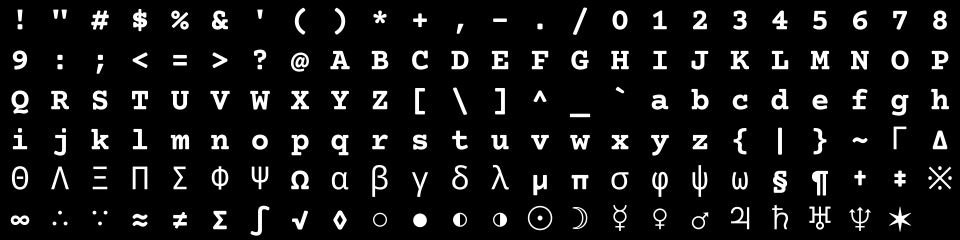

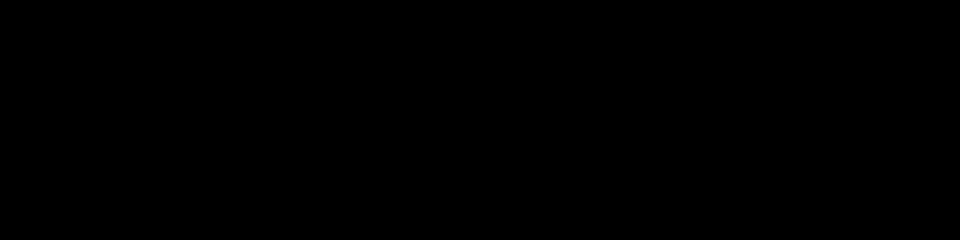

In [5]:
from IPython.display import Image, display
display(Image('run_full/targets.png')); display(Image('run_full/grown.png'))

In [6]:
from google.colab import files
files.download('run_full/weights.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>